In [2]:
# =========================================================
# Ribo-seq HDF5 → Count Matrix for DESeq2
# =========================================================

# ---------- LOAD LIBRARIES ----------
library(rhdf5)
library(dplyr)

# Close any stale HDF5 handles
h5closeAll()

# =========================================================
# FUNCTION
# =========================================================

load_riboseq_counts <- function(path) {

  # Get all gene names
  h5_genes <- h5ls(path)$name

  gene_counts <- list()

  for (gene in h5_genes) {

    # Read dataset
    ds <- h5read(path, gene)

    # Skip malformed datasets
    if (is.null(dim(ds))) {
      next
    }

    # Expecting N x 2 matrix:
    # column 1 = positions
    # column 2 = counts
    if (ncol(ds) < 2) {
      next
    }

    # Extract counts column
    counts <- ds[, 2]

    # Total ribosome counts per gene
    total <- sum(counts, na.rm = TRUE)

    gene_counts[[gene]] <- total
  }

  # Convert to dataframe
  df <- data.frame(
    gene = names(gene_counts),
    count = unlist(gene_counts),
    stringsAsFactors = FALSE
  )

  # Rename count column using filename
  sample_name <- tools::file_path_sans_ext(basename(path))
  colnames(df)[2] <- sample_name

  return(df)
}

# =========================================================
# LOAD FILES
# =========================================================

trans_rep1 <- load_riboseq_counts(
  "Translatome_CHX_rep1.h5"
)

trans_rep2 <- load_riboseq_counts(
  "Translatome_CHX_rep2.h5"
)

tom_rep1 <- load_riboseq_counts(
  "TOM_interactome_CHX_rep1.h5"
)

tom_rep2 <- load_riboseq_counts(
  "TOM_interactome_CHX_rep2.h5"
)


# =========================================================
# MERGE ALL SAMPLES
# =========================================================

counts <- trans_rep1 %>%
  full_join(trans_rep2, by = "gene") %>%
  full_join(tom_rep1, by = "gene") %>%
  full_join(tom_rep2, by = "gene")

# Replace NA with 0
counts[is.na(counts)] <- 0

# =========================================================
# CREATE COUNT MATRIX
# =========================================================

# Set rownames
rownames(counts) <- counts$gene

# Remove gene column
counts$gene <- NULL

# Convert to matrix
count_matrix <- as.matrix(counts)

# DESeq2 requires integers
storage.mode(count_matrix) <- "integer"

# =========================================================
# VIEW
# =========================================================

dim(count_matrix)

head(count_matrix)



h5closeAll()


[1] 15584     4

,Translatome_CHX_rep1,Translatome_CHX_rep2,TOM_interactome_CHX_rep1,TOM_interactome_CHX_rep2
A1BG,96,202,15,17
A2M,3,2,2,0
A3GALT2,1,1,7,0
A4GALT,30,46,2,4
AAAS,622,982,35,39
AACS,96,156,7,13


In [3]:
count_cols <- c(
  "Translatome_CHX_rep1",
  "Translatome_CHX_rep2",
 "TOM_interactome_CHX_rep1",
  "TOM_interactome_CHX_rep2"

)


coldata <- data.frame(
    condition = c("Translatome_CHX","Translatome_CHX","TOM_CHX","TOM_CHX"),
    row.names = c(
  "Translatome_CHX_rep1",
  "Translatome_CHX_rep2",
 "TOM_interactome_CHX_rep1",
  "TOM_interactome_CHX_rep2"
 
    )
)
coldata$condition <- factor(
    coldata$condition,
    levels = c("Translatome_CHX", "TOM_CHX")
)


In [4]:
library(DESeq2)

dds <- DESeqDataSetFromMatrix(countData = count_matrix,
                              colData = coldata,
                              design = ~ condition)

dds <- DESeq(dds)

res <- results(dds)
resOrdered <- res[order(res$pvalue), ]
head(resOrdered)


Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following object is masked from ‘package:dplyr’:

    explain


The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union



Attaching package: ‘BiocGenerics’


The following object is masked from ‘package:dplyr’:

    combine


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, is.unsorted, lapply, Map, mapply, match, mget,
    order, paste, pmax, pmax.int, pmin, pmin.int, Position, rank,
    rbind, Reduce, rownames, sapply, saveRDS, table, tapply, unique,
    unsplit, wh

log2 fold change (MLE): condition TOM CHX vs Translatome CHX 
Wald test p-value: condition TOM CHX vs Translatome CHX 
DataFrame with 6 rows and 6 columns
          baseMean log2FoldChange     lfcSE      stat       pvalue         padj
         <numeric>      <numeric> <numeric> <numeric>    <numeric>    <numeric>
ALDH18A1  4509.523        3.85033  0.081094   47.4798  0.00000e+00  0.00000e+00
CLPB      1274.693        3.57505  0.102881   34.7494 1.41371e-264 9.52485e-261
TRPM7    46627.209        9.95175  0.310480   32.0528 2.00874e-225 9.02261e-222
ABCB8     1178.741        3.64015  0.123801   29.4031 5.00549e-190 1.68622e-186
AARS2      671.490        3.41080  0.135540   25.1645 9.81667e-140 2.64559e-136
RAPGEF2    305.694        4.53161  0.184755   24.5276 7.49981e-133 1.68433e-129

In [5]:
summary(res)


out of 15584 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 2515, 16%
LFC < 0 (down)     : 1901, 12%
outliers [1]       : 0, 0%
low counts [2]     : 2109, 14%
(mean count < 1)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [6]:
resultsNames(dds)


[1] "Intercept"                           
[2] "condition_TOM_CHX_vs_Translatome_CHX"

In [7]:
resLFC <- lfcShrink(dds,
                    coef="condition_TOM_CHX_vs_Translatome_CHX",
                    type="apeglm")

resDF <- as.data.frame(resLFC)
resDF$gene <- rownames(resDF)
cat("DESeq2 summary:\n")
print(summary(resLFC))

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895



DESeq2 summary:

out of 15584 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 2515, 16%
LFC < 0 (down)     : 1901, 12%
outliers [1]       : 0, 0%
low counts [2]     : 2109, 14%
(mean count < 1)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results

NULL


In [8]:
sum(resDF$log2FoldChange < 0, na.rm = TRUE)
sum(resDF$padj < 0.1 & resDF$log2FoldChange < -2, na.rm = TRUE)

[1] 8026

[1] 25

Warning message:
“Removed 2109 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“ggrepel: 22 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


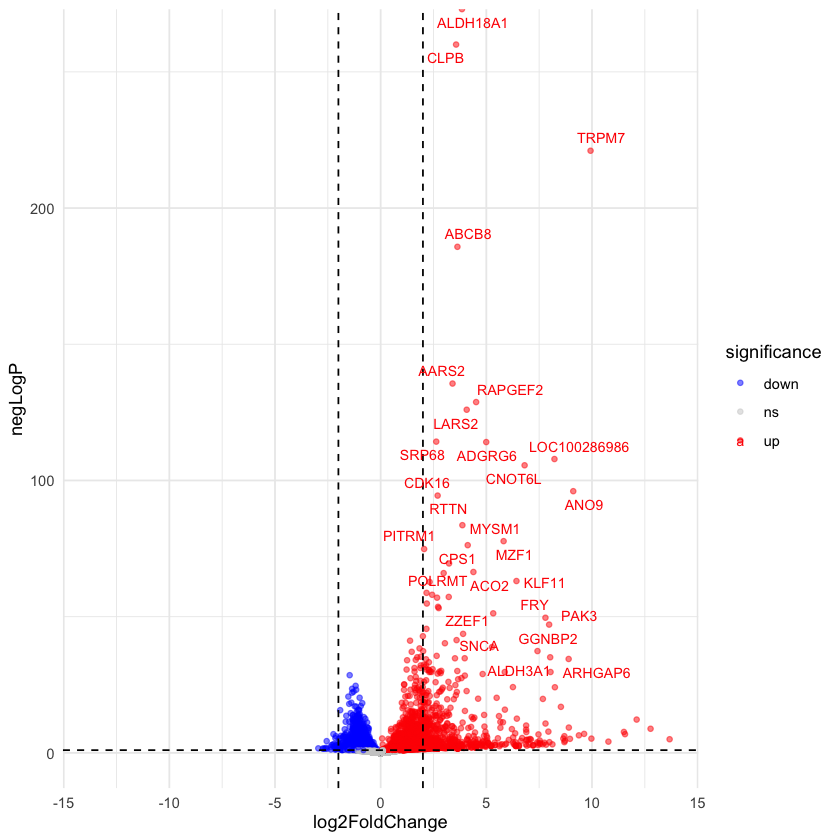

In [9]:
library(dplyr)
library(ggplot2)
library(ggrepel)

vol <- resDF %>%
  mutate(
    negLogP = -log10(padj),
    significance = case_when(
      !is.na(padj) &
      padj < 0.1 &
      log2FoldChange > 0 ~ "up",

      !is.na(padj) &
      padj < 0.1 &
      log2FoldChange < 0 ~ "down",

      TRUE ~ "ns"
    )
  )

toplabels <- vol %>%
  filter(!is.na(padj)) %>%
  arrange(padj) %>%
  slice_head(n = 50)

lfc_max <- max(abs(vol$log2FoldChange), na.rm = TRUE)

ggplot(vol,
       aes(
         x = log2FoldChange,
         y = negLogP,
         color = significance
       )) +

geom_point(alpha=.5, size=1.2) +

scale_color_manual(
  values=c(
    ns="grey80",
    up="red",
    down="blue"
  )
) +

geom_vline(
  xintercept=c(-2,2),
  linetype="dashed"
) +

geom_hline(
  yintercept=-log10(0.1),
  linetype="dashed"
) +

coord_cartesian(
  xlim=c(-lfc_max, lfc_max)
) +

geom_text_repel(
  data=toplabels,
  aes(label=gene),
  size=3
) +

theme_minimal()

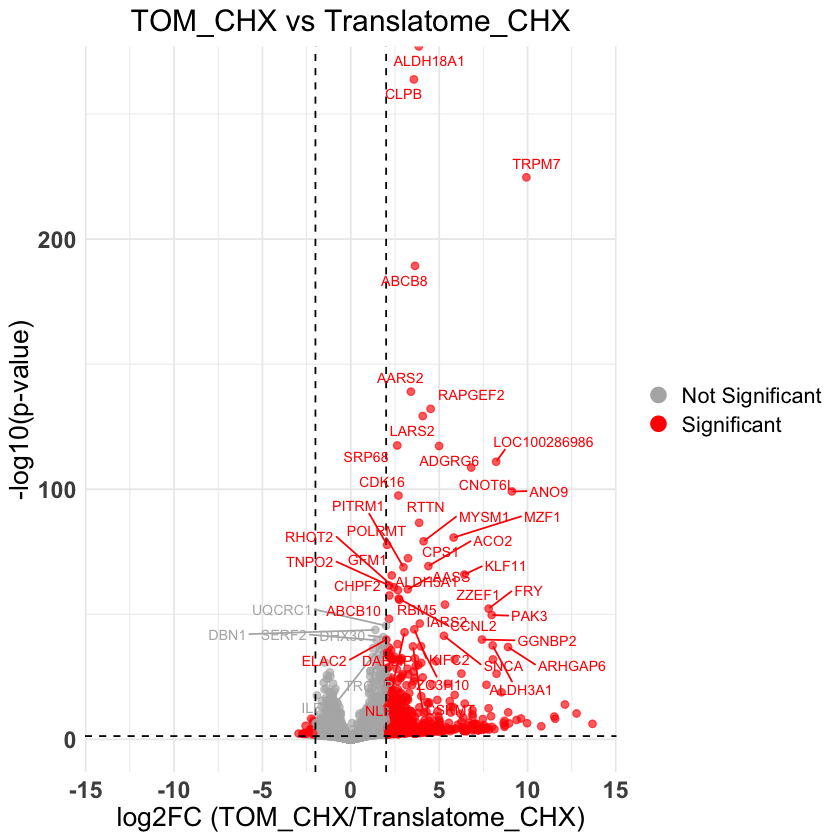

In [40]:
library(ggplot2)
library(ggrepel)


  vol <- resDF %>%
  mutate(
    negLogP = -log10(pvalue),
    significance = ifelse(
      !is.na(padj) &
      padj < 0.05 &
      abs(log2FoldChange) >= 2,
      "Significant",
      "Not Significant"
    )
  )

toplabels <- vol %>%
  filter(!is.na(padj)) %>%
  arrange(padj) %>%
  head(50)

lfc_max <- max(abs(vol$log2FoldChange), na.rm = TRUE)

volcano <- ggplot(
  vol,
  aes(
    x = log2FoldChange,
    y = negLogP,
    color = significance
  )
) +

geom_point(
  alpha = 0.65,
  size = 1.8
) +

scale_color_manual(
  values = c(
    "Not Significant" = "grey70",
    "Significant" = "red"
  ),
  name = NULL
) +

guides(
  color = guide_legend(
    override.aes = list(
      alpha = 1,
      size = 4
    )
  )
) +

geom_vline(
  xintercept = c(-2, 2),
  linetype = "dashed"
) +

geom_hline(
  yintercept = -log10(0.05),
  linetype = "dashed"
) +

coord_cartesian(
  xlim = c(-lfc_max, lfc_max)
) +

geom_text_repel(
  data = toplabels,
  aes(label = gene),
  size = 3,
  max.overlaps = 100,
  box.padding = 0.3
) +

labs(
  title = "TOM_CHX vs Translatome_CHX",
  x = "log2FC (TOM_CHX/Translatome_CHX)",
  y = "-log10(p-value)"
) +

theme_minimal() +

theme(
  plot.title = element_text(
    size = 18,
    
    hjust = 0.5
  ),
  axis.title = element_text(
    size = 16,
   
  ),
  axis.text = element_text(
    size = 14,
    face = "bold"
  ),
  legend.title = element_blank(),
  legend.text = element_text(
    size = 13
   
  )
)

volcano

In [42]:
ggsave( "DE_plot_with_chx.png",volcano, width= 9.5, height = 7, dpi=300)

In [9]:
res_sig <- resDF %>% filter(!is.na(padj) & padj < 0.05 & abs(log2FoldChange) >=2) %>% arrange(padj)



In [11]:
localization<- read.csv("all_genes_location_with_chx.csv")
res_sig <- res_sig %>%
  left_join(
    localization %>%
      select(gene_old, localization),
    by = c("gene" = "gene_old")
  )


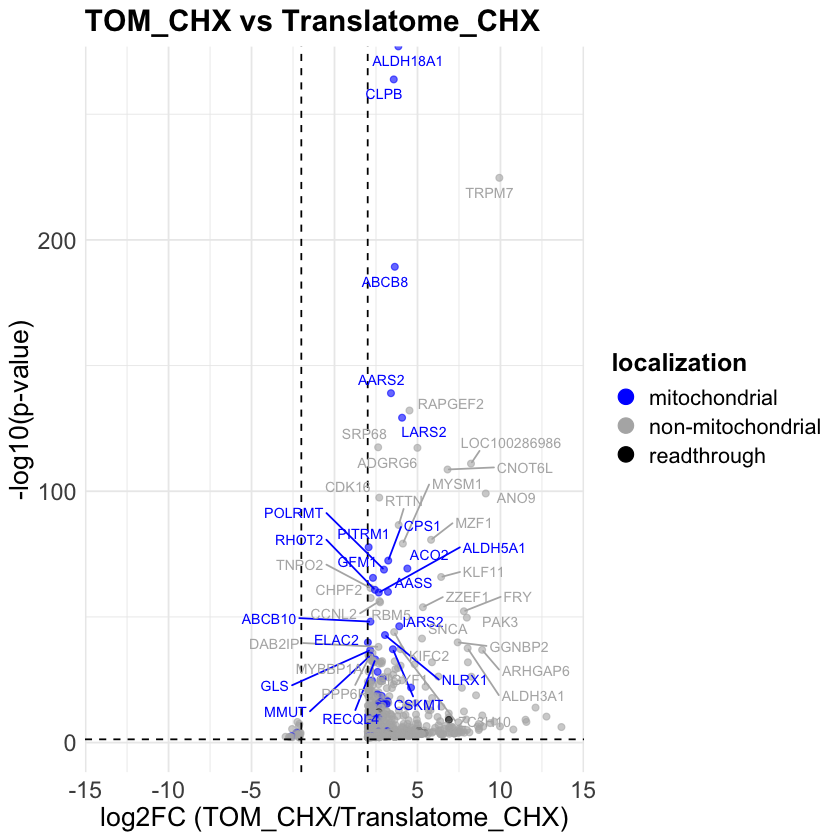

In [12]:
library(ggplot2)
library(ggrepel)

vol <- res_sig %>%
  mutate(
    negLogP = -log10(pvalue)
  )

toplabels <- vol %>%
  filter(!is.na(padj)) %>%
  arrange(padj) %>%
  head(50)

lfc_max <- max(abs(vol$log2FoldChange), na.rm = TRUE)

volcano <- ggplot(
  vol,
  aes(
    x = log2FoldChange,
    y = negLogP,
    color = localization
  )
) +

geom_point(
  alpha = 0.6,
  size = 1.6
) +

scale_color_manual(
  values = c(
    "mitochondrial" = "blue",
    "non-mitochondrial" = "gray70",
    "readthrough" = "black"
  ),
  na.value = "red"
) +

guides(
  color = guide_legend(
    override.aes = list(
      alpha = 1,
      size = 4
    )
  )
) +

geom_vline(
  xintercept = c(-2, 2),
  linetype = "dashed"
) +

geom_hline(
  yintercept = -log10(0.05),
  linetype = "dashed"
) +

coord_cartesian(
  xlim = c(-lfc_max, lfc_max)
) +

geom_text_repel(
  data = toplabels,
  aes(label = gene),
  size = 3,
  max.overlaps = 100,
  box.padding = 0.3
) +

labs(
  title = "TOM_CHX vs Translatome_CHX",
  x = "log2FC (TOM_CHX/Translatome_CHX)",
  y = "-log10(p-value)"
) +

theme_minimal() +

theme(
  plot.title = element_text(size = 18, face = "bold"),
  axis.title = element_text(size = 16),
  axis.text = element_text(size = 14),
  legend.title = element_text(size = 15, face = "bold"),
  legend.text = element_text(size = 13)
)

volcano

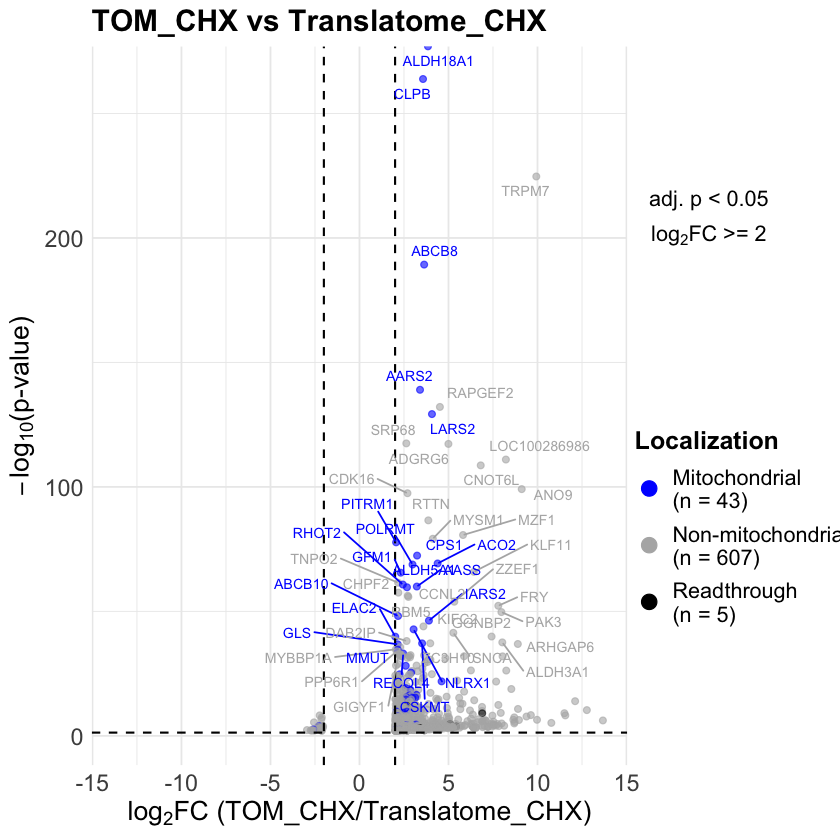

In [16]:
library(ggplot2)
library(ggrepel)
library(dplyr)
library(cowplot)

# --------------------------------------------------
# Prepare data
# --------------------------------------------------

vol <- res_sig %>%
  mutate(
    localization = as.character(localization),
    negLogP = -log10(pvalue)
  )

# --------------------------------------------------
# Count proteins in each localization
# --------------------------------------------------

localization_counts <- table(vol$localization)

# --------------------------------------------------
# Top 50 proteins for labeling
# --------------------------------------------------

toplabels <- vol %>%
  filter(!is.na(padj)) %>%
  arrange(padj) %>%
  head(50)

# --------------------------------------------------
# Maximum absolute log2FC
# --------------------------------------------------

lfc_max <- max(
  abs(vol$log2FoldChange),
  na.rm = TRUE
)

# --------------------------------------------------
# Legend labels
# --------------------------------------------------

legend_labels <- c(

  "mitochondrial" =
    paste0(
      "Mitochondrial\n(n = ",
      localization_counts["mitochondrial"],
      ")"
    ),

  "non-mitochondrial" =
    paste0(
      "Non-mitochondrial\n(n = ",
      localization_counts["non-mitochondrial"],
      ")"
    ),

  "readthrough" =
    paste0(
      "Readthrough\n(n = ",
      localization_counts["readthrough"],
      ")"
    )
)

# --------------------------------------------------
# Volcano plot
# --------------------------------------------------

volcano <- ggplot(
  vol,
  aes(
    x = log2FoldChange,
    y = negLogP,
    color = localization
  )
) +

  geom_point(
    alpha = 0.6,
    size = 1.6
  ) +

  # ------------------------------------------------
  # Existing legend
  # ------------------------------------------------

  scale_color_manual(
    name = "Localization",

    values = c(
      "mitochondrial" = "blue",
      "non-mitochondrial" = "gray70",
      "readthrough" = "black"
    ),

    breaks = c(
      "mitochondrial",
      "non-mitochondrial",
      "readthrough"
    ),

    labels = legend_labels,

    na.translate = FALSE
  ) +

  guides(
    color = guide_legend(
      override.aes = list(
        alpha = 1,
        size = 4
      )
    )
  ) +

  # ------------------------------------------------
  # log2FC cutoff lines
  # ------------------------------------------------

  geom_vline(
    xintercept = c(-2, 2),
    linetype = "dashed",
    linewidth = 0.6,
    color = "black"
  ) +

  # ------------------------------------------------
  # adjusted p-value cutoff
  # ------------------------------------------------

  geom_hline(
    yintercept = -log10(0.05),
    linetype = "dashed",
    linewidth = 0.6,
    color = "black"
  ) +

  # ------------------------------------------------
  # X-axis limits
  # ------------------------------------------------

  coord_cartesian(
    xlim = c(-lfc_max, lfc_max)
  ) +

  # ------------------------------------------------
  # Gene labels
  # ------------------------------------------------

  geom_text_repel(
    data = toplabels,
    aes(label = gene),
    size = 3,
    max.overlaps = 100,
    box.padding = 0.3
  ) +

  # ------------------------------------------------
  # Axis labels
  # ------------------------------------------------

  labs(
    title = "TOM_CHX vs Translatome_CHX",

    x = expression(
      log[2] * "FC (TOM_CHX/Translatome_CHX)"
    ),

    y = expression(
      -log[10] * "(p-value)"
    )
  ) +

  # ------------------------------------------------
  # Theme
  # ------------------------------------------------

  theme_minimal() +

  theme(
    plot.title = element_text(
      size = 18,
      face = "bold"
    ),

    axis.title = element_text(
      size = 16
    ),

    axis.text = element_text(
      size = 14
    ),

    legend.title = element_text(
      size = 15,
      face = "bold"
    ),

    legend.text = element_text(
      size = 13
    ),

    legend.key.height = unit(
      1.2,
      "cm"
    ),

    legend.position = "right"
  )


# ==================================================
# Extract the ORIGINAL legend
# ==================================================

legend <- get_legend(volcano)


# ==================================================
# Remove legend from volcano
# ==================================================

volcano_no_legend <- volcano +
  theme(
    legend.position = "none"
  )


# ==================================================
# Criteria ABOVE legend
# ==================================================

criteria <- ggdraw() +

  draw_label(
    expression(
      atop(
        "adj. p < 0.05",
        log[2] * "FC >= 2"
      )
    ),
    x = 0,
    y = 0.001,
    hjust = 0,
    vjust = 0.5,
    size = 13,
    fontface = "bold"
  )


# ==================================================
# Stack criteria directly above legend
# ==================================================

legend_with_criteria <- plot_grid(
  criteria,
  legend,
  ncol = 1,
  
  rel_heights = c(0.35, 1)
)


# ==================================================
# Final plot with padding between graph and legend
# ==================================================

final_plot <- plot_grid(
  volcano_no_legend,
  NULL,
  legend_with_criteria,
  ncol = 3,

  # graph | padding | legend
  rel_widths = c(
    1,
    0.02,
    0.30
  )
)


# ==================================================
# Display
# ==================================================

final_plot


# ==================================================
# Save
# ==================================================

ggsave(
  "volcano_TOM_vs_Translatome_CHX.png",
  final_plot,
  width = 8.5,
  height = 6,
  dpi = 600,
  bg = "white"
)


In [32]:
ggsave( "DE_plot_chx_localization.png",volcano, width= 9.5, height = 7, dpi=300)

In [13]:
dim(res_sig)
table(res_sig$localization)

[1] 655   7


    mitochondrial non-mitochondrial       readthrough 
               43               607                 5 

In [14]:
write.csv(res_sig, "DE_significant_CHX.csv", row.names = FALSE)